# Do nonlinear scores provide more useful UCL warning?

The practical question is event detection far enough ahead, under a controlled alert burden. Compare ranking and warning separately. 2024–2025 is exploratory transfer, not prospective confirmation.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
while not (ROOT/'src/injury_analysis').exists() and ROOT!=ROOT.parent:
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.injury_analysis.ucl_nonlinear_common import OUT, CACHE, CFG, read_table
pd.set_option('display.max_columns',20)
protocol=json.loads((OUT/'frozen_protocol.json').read_text())
def show(name,n=25):display(read_table(name).head(n))
def plot(name):display(Image(filename=str(OUT/'figures'/(name+'.png')),width=1150))


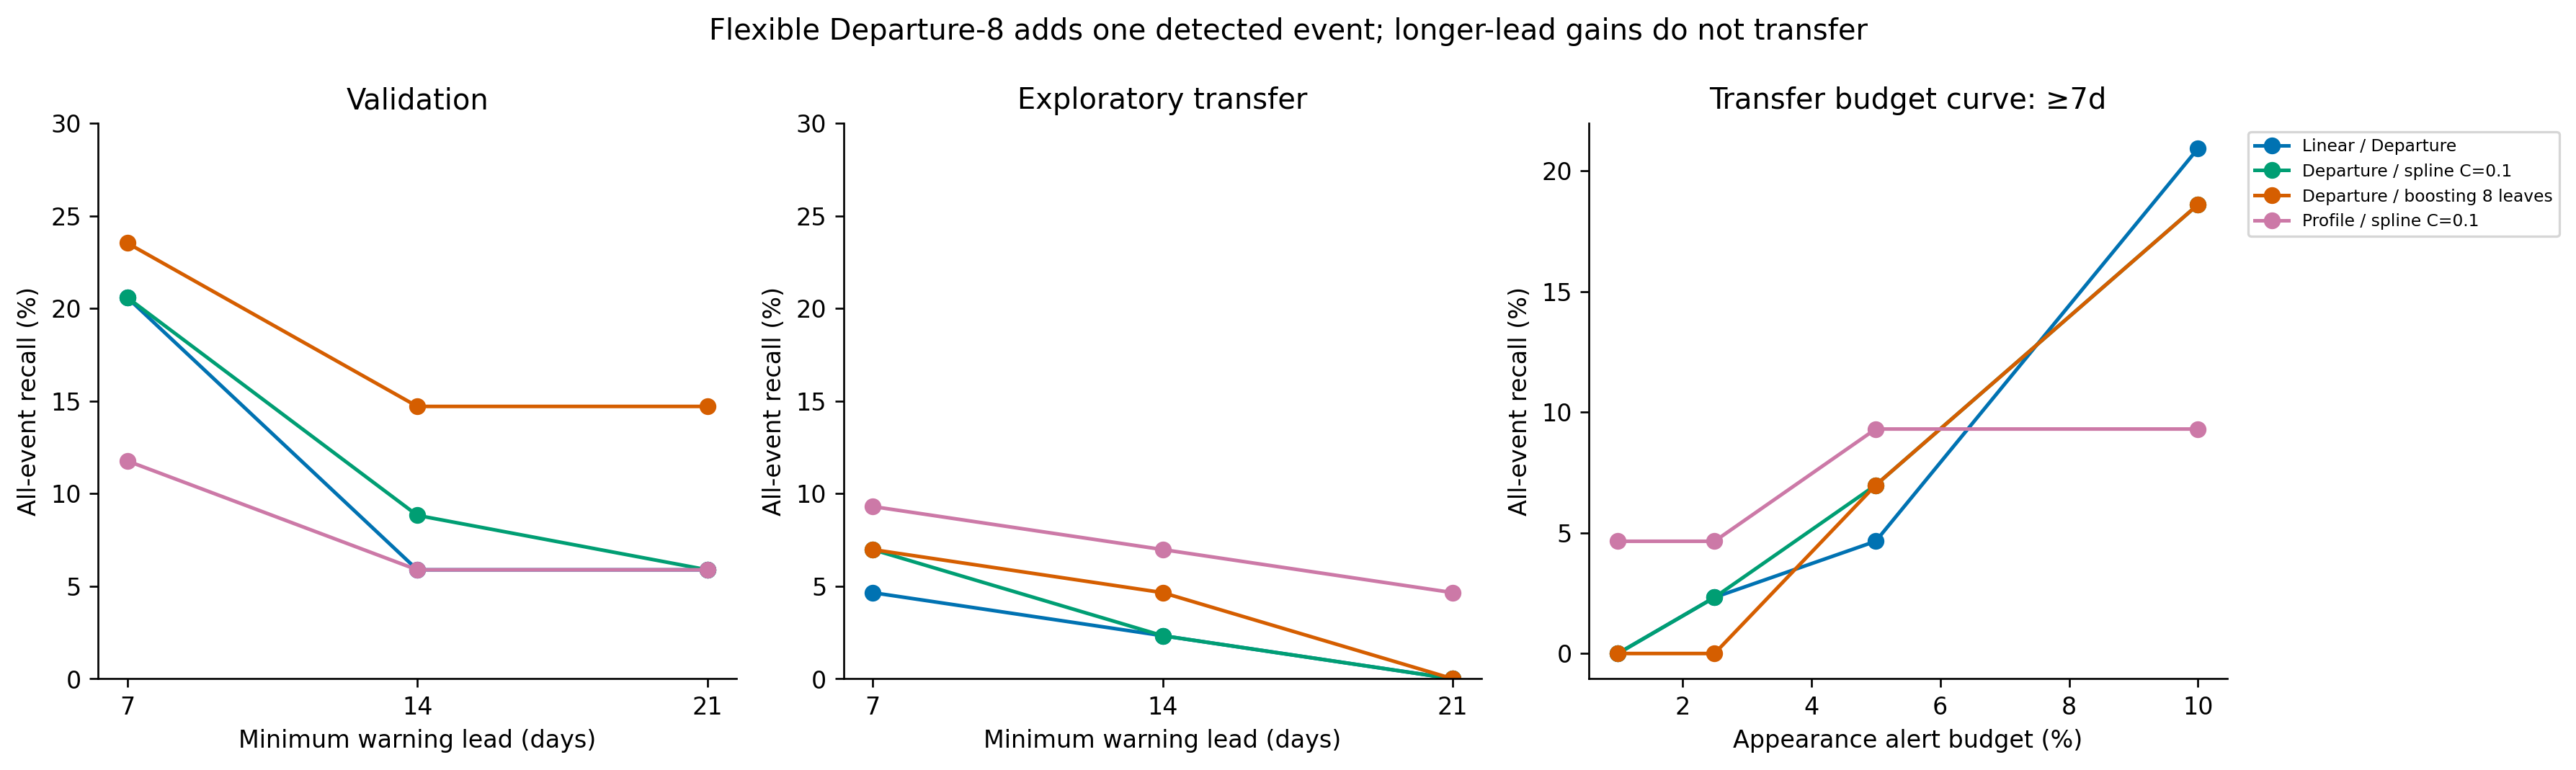

,partition,model_id,minimum_lead,alerts,alerted_events,qualifying_events,median_warning_lead_days,alerts_per_detected_event,false_alert_fraction
2,validation,Departure__Boosting__8,7,1443,8,34,26.5,180.375000,0.990991
7,validation,Departure__Boosting__8,14,1443,5,34,28.0,288.600000,0.990991
12,validation,Departure__Boosting__8,21,1443,5,34,28.0,288.600000,0.990991
17,validation,Linear|Departure,7,1443,7,34,12.0,206.142857,0.988912
22,validation,Linear|Departure,14,1443,2,34,28.0,721.500000,0.988912
27,validation,Linear|Departure,21,1443,2,34,28.0,721.500000,0.988912
32,validation,Departure__Spline__0p1,7,1443,7,34,12.0,206.142857,0.988912
37,validation,Departure__Spline__0p1,14,1443,3,34,26.0,481.000000,0.988912
42,validation,Departure__Spline__0p1,21,1443,2,34,26.5,721.500000,0.988912
47,validation,Linear|Stable 62,7,1443,3,34,15.0,481.000000,0.988219


In [2]:
plot('02_warning_and_alert_budget')
w=read_table('leader_warning_comparison')
display(w.loc[w.alert_rate.eq(.05)&w.policy.eq('retrospective_budget'),['partition','model_id','minimum_lead','alerts','alerted_events','qualifying_events','median_warning_lead_days','alerts_per_detected_event','false_alert_fraction']])

At a 5% budget, departure trees warn on 8/34 validation events and 3/43 transfer events ≥7 days ahead, versus 7/34 and 2/43 for logistic regression. Spline departure warns on 7/34 and 3/43. The differences are small relative to uncertainty. The tree’s ≥21-day warnings drop from 5/34 to 0/43. Conditional lead-time medians among a few detected events do not imply broadly earlier detection.

In [3]:
show('warning_uncertainty',n=30)
g=read_table('paired_uncertainty')
display(g.loc[g.model_id.isin(list(protocol['warning_leaders'].values())+list(protocol['ranking_leaders'].values()))])

,partition,model_id,minimum_lead,detected,events,recall,ci_low,ci_high
0,test,Departure__Boosting__8,7,3,43,0.069767,0.000000,0.144686
1,test,Departure__Boosting__8,14,2,43,0.046512,0.000000,0.116279
2,test,Departure__Boosting__8,21,0,43,0.000000,0.000000,0.000000
3,test,Departure__Spline__0p1,7,3,43,0.069767,0.000000,0.146341
4,test,Departure__Spline__0p1,14,1,43,0.023256,0.000000,0.073171
5,test,Departure__Spline__0p1,21,0,43,0.000000,0.000000,0.000000
6,test,Linear|Departure,7,2,43,0.046512,0.000000,0.120572
7,test,Linear|Departure,14,1,43,0.023256,0.000000,0.072343
8,test,Linear|Departure,21,0,43,0.000000,0.000000,0.000000
9,test,Linear|Stable 62,7,9,43,0.209302,0.093023,0.333333


,partition,model_id,reference,metric,mean_difference,ci_low,ci_high,fraction_positive
4,validation,Departure__Boosting__8,Linear|Departure,average_precision,-0.000922,-0.003299,0.000562,0.163333
5,validation,Departure__Boosting__8,Linear|Departure,event_recall_7_30d,0.028922,-0.058824,0.133088,0.623333
6,validation,Departure__Spline__0p1,Linear|Departure,average_precision,-0.000640,-0.002859,0.000831,0.276667
7,validation,Departure__Spline__0p1,Linear|Departure,event_recall_7_30d,-0.004510,-0.147059,0.147059,0.426667
28,validation,Profile__Spline__0p1,Linear|Profile,average_precision,0.019799,-0.001848,0.066071,0.833333
29,validation,Profile__Spline__0p1,Linear|Profile,event_recall_7_30d,0.115098,0.029412,0.235294,0.986667
30,validation,Profile__Boosting__4,Linear|Profile,average_precision,0.034300,-0.001449,0.119821,0.910000
31,validation,Profile__Boosting__4,Linear|Profile,event_recall_7_30d,0.088824,0.000000,0.205882,0.946667
36,test,Departure__Boosting__8,Linear|Departure,average_precision,-0.000495,-0.001700,0.001156,0.183333
37,test,Departure__Boosting__8,Linear|Departure,event_recall_7_30d,0.020248,-0.047619,0.096458,0.583333


In [4]:
show('operational_burden',n=30)
show('subgroup_diagnostics',n=25)

,partition,model_id,eligible_rows,alerts,actual_alert_rate,unknown_outcome_alerts,known_negative_alerts,known_positive_alerts,warned_events,qualifying_events
0,validation,Background__Boosting__4,39725,4934,0.124204,3489,1429,16,3,34
1,validation,Linear|Background,39725,1686,0.042442,242,1435,9,2,34
2,validation,Background__Spline__0p1,39725,1837,0.046243,393,1427,17,2,34
3,validation,Departure__Boosting__8,39725,1977,0.049767,533,1431,13,8,34
4,validation,Linear|Departure,39725,1980,0.049843,536,1428,16,7,34
5,validation,Departure__Spline__0p1,39725,1993,0.050170,549,1428,16,7,34
6,validation,Previous_62__Boosting__2,39725,3152,0.079346,1708,1426,18,4,34
7,validation,Linear|Previous 62,39725,2021,0.050875,577,1430,14,3,34
8,validation,Previous_62__Spline__0p1,39725,1925,0.048458,481,1436,8,3,34
9,validation,Profile__Boosting__2,39725,2014,0.050699,564,1431,19,3,34


,partition,model_id,subset,event_denominator,rows,pitchers,positive_rows,represented_events,prevalence,average_precision,roc_auc,brier_score,mean_predicted_risk,calibration_bias,pr_lift,qualifying_events,alerted_events,injury_event_recall
0,validation,Linear|Departure,seen in training,subgroup observable events,22975,553,108,21,0.004701,0.007786,0.568892,0.004677,0.003980,-0.000721,1.656399,17,6,0.352941
1,validation,Linear|Departure,unseen in training,subgroup observable events,5900,249,30,4,0.005085,0.006685,0.522141,0.005062,0.003812,-0.001273,1.314695,3,1,0.333333
2,validation,Linear|Departure,starter,subgroup observable events,6900,399,69,16,0.010000,0.017431,0.613841,0.009921,0.004118,-0.005882,1.743147,12,2,0.166667
3,validation,Linear|Departure,reliever,subgroup observable events,21975,646,69,9,0.003140,0.004250,0.483681,0.003134,0.003892,0.000752,1.353545,8,4,0.500000
4,validation,Departure__Spline__0p1,seen in training,subgroup observable events,22975,553,108,21,0.004701,0.007188,0.597196,0.004679,0.003992,-0.000709,1.529207,17,5,0.294118
5,validation,Departure__Spline__0p1,unseen in training,subgroup observable events,5900,249,30,4,0.005085,0.006585,0.452669,0.005068,0.003814,-0.001271,1.294987,3,2,0.666667
6,validation,Departure__Spline__0p1,starter,subgroup observable events,6900,399,69,16,0.010000,0.015495,0.619236,0.009923,0.004106,-0.005894,1.549472,12,2,0.166667
7,validation,Departure__Spline__0p1,reliever,subgroup observable events,21975,646,69,9,0.003140,0.004074,0.500505,0.003136,0.003909,0.000769,1.297329,8,4,0.500000
8,validation,Departure__Boosting__8,seen in training,subgroup observable events,22975,553,108,21,0.004701,0.006989,0.569086,0.004679,0.003926,-0.000775,1.486868,17,7,0.411765
9,validation,Departure__Boosting__8,unseen in training,subgroup observable events,5900,249,30,4,0.005085,0.005448,0.469239,0.005070,0.003793,-0.001291,1.071533,3,1,0.333333


Retrospective top-N budgets differ from frozen numeric thresholds. Realized alert rates can change in transfer. The operational table includes all eligible landmarks and preserves unknown outcome alerts; it does not assume that censored rows were healthy. Subgroup recall denominators use observable events and are not directly comparable to primary all-event recall.

In [5]:
g=read_table('training_refit_metrics')
display(g.groupby('model_id')[['average_precision','injury_event_recall']].agg(['mean','min','max']))

average_precision                      \
                                    mean       min       max   
model_id                                                       
Departure__Boosting__8          0.005738  0.005134  0.006567   
Departure__Spline__0p1          0.006591  0.005828  0.007164   
Linear|Departure                0.007168  0.006401  0.007650   
Linear|Profile                  0.005617  0.004507  0.006520   
Linear|Stable 62                0.009019  0.006983  0.013203   
Profile__Boosting__4            0.006912  0.004457  0.010725   
Profile__Spline__0p1            0.016346  0.005807  0.039401   

                       injury_event_recall                      
                                      mean       min       max  
model_id                                                        
Departure__Boosting__8            0.187500  0.117647  0.264706  
Departure__Spline__0p1            0.202206  0.147059  0.294118  
Linear|Departure                  0.158088  0.117647  0.176471  
Linear|Profile                    0.018382  0.000000  0.058824  
Linear|Stable 62                  0.077206  0.029412  0.176471  
Profile__Boosting__4              0.047794  0.000000  0.088235  
Profile__Spline__0p1              0.069853  0.029412  0.117647

**Conclusion:** Flexible models reveal curved profile associations and some fitted interactions, but no robust, broadly transferable improvement in practical UCL warning is established. The most impressive spline AP result is concentrated in very few pitchers. Keep the original linear departure/broader benchmarks, retain frozen nonlinear departure challengers, and treat the profile spline as a separate composition-sensitive hypothesis. Do not choose a new winner from transfer results.

In [6]:
from src.injury_analysis.ucl_nonlinear_reporting import validate
checks=validate()
display(pd.Series({'validation_checks':len(checks),'passed':sum(c['passed'] for c in checks)}))
show('validation_checks',n=12)

validation_checks    81
passed               81
dtype: int64

,check,passed,detail
0,Source database and canonical inputs preserved,True,NaN
1,"All prior reports, notebooks, source modules a...",True,NaN
2,Unchanged validation linear scores/metrics: Ba...,True,NaN
3,Unchanged test linear scores/metrics: Background,True,NaN
4,Unchanged validation linear scores/metrics: Pr...,True,NaN
5,Unchanged test linear scores/metrics: Profile,True,NaN
6,Unchanged validation linear scores/metrics: De...,True,NaN
7,Unchanged test linear scores/metrics: Departure,True,NaN
8,Unchanged validation linear scores/metrics: Pr...,True,NaN
9,Unchanged test linear scores/metrics: Profile ...,True,NaN


In [7]:
display(Markdown((OUT/'summary.md').read_text()))

# Nonlinear UCL model evaluation

## Design and models

This additive stage preserves the refined UCL endpoint, first-event competing-injury rules, chronological partitions, 60-day embargo, completed-appearance cutoff, source missingness and frozen feature representations. No previous analysis is replaced. The 30-day risk sets are unchanged: 87,332 training rows (59 represented events), 28,875 validation rows (25 represented events), and 29,349 exploratory-transfer rows (28 represented events). All-event warning denominators remain 34 validation and 43 transfer episodes; only 20 and 28 have a 7–30d opportunity.

Seven frozen representations were compared: background, profile, departure-8, profile+departure, trajectory-enhanced profile+departure, previous-62 and stable-62. Existing L2 logistic models were reused exactly. The nonlinear search fitted 35 candidates: cubic additive spline logistic models at C=0.1 or 1; histogram gradient boosting with 2, 4 or 8 leaves, depth 1/2/3, 150 iterations, learning rate .05, minimum leaf 200 and L2=10. Stumps are additive on log-odds; larger trees permit interactions. Training-only clipping, median imputation and missingness indicators were retained. There was no random validation split, synthetic injury, class weighting, neural network or new feature selection.

Settings were selected solely on 2022–2023 validation warnings at a 5% budget, with AP above prevalence and simple-model tie breaks. AP leaders were frozen separately as ranking hypotheses. Exact fits, settings and numeric validation thresholds were written before new 2024–2025 predictions. No model was refitted on validation. The already examined transfer period is exploratory; 2026 was not evaluated.

## Principal results

| Hypothesis | Validation AP | Transfer AP | Validation ≥7d warnings | Transfer ≥7d warnings |
|---|---:|---:|---:|---:|
| Linear departure-8 | 0.00727 | 0.00584 | 7/34 | 2/43 |
| Spline departure-8, C=.1 | 0.00679 | 0.00571 | 7/34 | 3/43 |
| Boosted departure-8, 8 leaves | 0.00643 | 0.00533 | 8/34 | 3/43 |
| Spline profile, C=.1 (AP leader) | 0.02466 | 0.04451 | 4/34 | 4/43 |
| Boosted profile, 4 leaves (AP leader) | 0.02943 | 0.00646 | 3/34 | 1/43 |
| Linear stable-62 | 0.01092 | 0.01846 | 3/34 | 9/43 |

The warning leaders are departure models, not the profile AP leaders. Nonlinear departure models do not improve AP; the one-event warning gain has wide paired uncertainty including zero. At ≥14 days, departure-tree warnings are 5/34 validation versus 2/43 transfer; at ≥21 days, 5/34 versus 0/43. Its conditional first-warning median is 26.5 days in validation and 17 days in transfer, among only 8 and 3 detected events. There are roughly 180 and 489 alerts per detected event at 5% budget. A longer median among a few detections is not generally earlier detection.

### A large AP gain is concentrated in very few pitchers

The profile spline is the clearest apparent nonlinear ranking improvement, but one event supplies 68.1% of validation AP and another 79.1% of transfer AP. Removing the corresponding pitcher changes validation AP from 0.02466 to 0.00598 and transfer AP from 0.04451 to 0.00731. Those pitchers are Humberto Castellanos (2022) and Justin Martinez (2025); identifiers and raw training-relative profile values are retained for audit. This diagnostic removes that pitcher's positive and negative rows; it is not a new tuned model or an excuse to discard the cases.

The paired whole-pitcher AP-increment intervals include zero in both periods. Across eight training refits, profile-spline validation AP ranges from 0.00581 to 0.03940. The profile-tree AP leader falls from training AP 0.12947 to validation 0.02943 and transfer 0.00646; its refit validation AP is 0.00446–0.01073. These are material composition sensitivity and overfitting warnings, despite impressive single-fit AP.

### Nonlinearity versus interaction

Additive splines can recover curved profile associations without interactions. The strongest profile-spline validation permutation effects involve historical release-Z variability, release-X position, extension, age and experience. These correlated, persistent profile variables do not establish short-term imminence. The spline-profile gain is too concentrated to claim a reproducible population-level susceptibility relationship.

Departure models retain a lower-velocity/higher-risk direction already present in logistic regression. Curved extension, release-variability and spin effects occur in flexible fits, but they do not consistently increase ranking or warning. Curves are training-supported accumulated local log-odds effects with eight-refit ranges, not medical thresholds. Marginal permutation importance is conditional on the fitted model and can be shared or distorted by correlated features.

The warning-selected profile+departure and previous-62 boosting models are stumps. Their learned log-odds interaction contrasts are zero by construction. Deeper alternatives did not improve their validation warning counts. Trees can fit velocity×release-variability and profile mechanical interactions, but local interaction maps and their refit variability do not establish useful incremental warning. No interaction is interpreted as a biomechanical mechanism.

The broader feature sets do not benefit uniformly: stable-62 nonlinear selections have lower validation and transfer AP than linear stable-62; previous-62 splines are approximately tied with the linear benchmark in transfer AP but lower in validation. Trajectory-enhanced models also fail to establish a consistent warning advantage. The comparison supports curved profile associations in a subset of cases, not a general need for complex injury interactions.

## Calibration, burden and uncertainty

Brier scores, calibration curves with validation-defined bins, warning budgets at 1/2.5/5/10%, ≥7/14/21d recall, first-warning event details, false/nonactionable alert fractions and alerts per detection are saved. Rare outcomes make small Brier differences hard to interpret; a high AP alone does not establish calibration. Fixed validation numeric thresholds are evaluated separately from retrospective top-N budgets. All-eligible-appearance burden includes unknown outcome alerts without assigning healthy labels.

Conditional uncertainty uses 300 paired whole-pitcher resamples; eight common whole-pitcher training refits assess fit variability without retuning. Leave-one-injured-pitcher-out diagnostics, event AP contributions, role and unseen-pitcher checks expose composition sensitivity. Eight-refit effect ranges are descriptive, not 95% confidence intervals. Selection uncertainty and repeated exploratory comparisons remain; an empirical zero-warning bootstrap interval is not a population certainty bound.

## What to retain

Nonlinear modeling does **not materially change the conclusion that reliable UCL early warning has not been demonstrated**. Model form may affect a few profile-based rankings, but it is not established as the main warning bottleneck. Endpoint uncertainty, heterogeneous events, limited positive-event counts and missing direct biomechanical measurements remain plausible constraints; this study cannot identify their causal contributions.

Keep the original linear departure-8 and broader linear benchmarks frozen. Retain spline departure-8 and the shallow departure-tree as prespecified nonlinear warning challengers, and the profile spline as a separate composition-sensitive ranking hypothesis. Do not promote it to a deployed detector based on AP. Exact model artifacts and thresholds are in `frozen_protocol.json`; the next useful test is a genuinely future, complete post-freeze cohort with prospectively archived injury evidence and no retuning.

## Artifacts and rerun

- `notebooks/ucl_nonlinear/`: design/comparison; effects/stability; warning/transfer synthesis.
- `reports/ucl_nonlinear/figures/`: six focused PNG/PDF figures.
- `reports/ucl_nonlinear/tables/`: tuning, paired uncertainty, warning/calibration, influence, local effects, interactions, refits and validation.
- `data/injury/analysis/ucl_nonlinear/`: fitted candidate/refit models, predictions and the training-only interpretation reference.
- Methods and source references: `docs/ucl_nonlinear_methods.md`.

Resume with `.venv/bin/python -m src.injury_analysis.ucl_nonlinear_pipeline`. Execute notebooks with `.venv/bin/python scripts/run_injury_analysis_notebooks.py --suite ucl-nonlinear`. Completed checkpoints are reused; changed inputs fail loudly.
